<img src="https://raw.githubusercontent.com/carubbi/MQ/b58af070c45fb17b77640c06c0016859ad366b4d/notebooks/assets/imgs/UNIFOR_logo.png" width="400">
<br>
<b>
<font size="6" face="arial" color="blue">
    Graduação em Ciência da Computação
</font>
</b>
<br>
<b>
<font size="4" face="arial">
    Disciplina: Métodos Quantitativos em Computação
</font>
</b>

**Orientador: Prof. Me. Ricardo Carubbi** <br>
*Docente da Graduação e Pós-Graduação em Ciência de Dados e Inteligência Artificial*<br>
*Laboratório de Ciência de Dados e Inteligência Artificial*<br>
*Universidade de Fortaleza*<br>

# Aula 2 — Variáveis aleatórias discretas e contínuas e acompanhamento final da AP1

## 1. Objetivos de aprendizagem

Ao final da aula, o aluno será capaz de:

- associar os resultados de um experimento a valores numéricos por meio de uma variável aleatória e distinguir o espaço amostral do conjunto de valores possíveis da variável;
- construir e verificar uma distribuição discreta pequena;
- implementar diretamente as somas de esperança e variância discretas e conferir os resultados com um pacote;
- distinguir uma contagem discreta de uma medição contínua, aproximar numericamente a esperança e a variância contínuas por implementação direta e conferir os resultados com um pacote.

## 2. Agenda

1. Conceito geral de variável aleatória — 10 min
2. Caso discreto: distribuição, esperança e variância — 25 min
3. Caso contínuo: intervalos, esperança e variância — 35 min
4. Acompanhamento final da AP1 — 30 min

Os primeiros 70 minutos correspondem ao conteúdo deste notebook. Os 30 minutos finais do encontro são reservados ao acompanhamento da AP1.

**Pergunta da aula:** 

> **Como representar numericamente um resultado incerto e interpretar sua distribuição?**


A Aula 1 introduziu experimento, espaço amostral e evento. Nesta aula, distinguimos uma contagem de uma medição e usamos as probabilidades declaradas pelo modelo, sem tratá-las como frequências observadas.

## 3. Variável aleatória

Uma variável aleatória associa um número a cada resultado possível de um experimento (BARBETTA; REIS; BORNIA, 2010, p. 117–120).

Ao lançar duas moedas, pode indicar quantas caras saíram. Em uma aplicação, pode indicar o tempo de resposta de uma requisição.

Antes do experimento, sabemos o que vamos observar, mas não qual valor obteremos. Se repetirmos cada experimento muitas vezes, que valor encontraremos em média? Quanto os resultados variarão?

Essas perguntas nos levam à **esperança** e à **variância**. Em estatística, elas são chamadas de **momentos**, médias teóricas de potências dos valores ou de seus desvios (MORETTIN; BUSSAB, 2010, p. 190).

### 3.1 Retomada de eventos aleatórios

Em um lançamento de moeda, o evento $A$ pode ser “sair cara”. Se a **probabilidade teórica** é $p=\mathbb P(A)$, a chance do evento complementar é $\mathbb P(A^c)=1-p$. Depois de $n$ lançamentos, a **frequência observada** de caras é o número de caras dividido por $n$. Ela pode diferir de $p$.

O gráfico pronto abaixo compara a probabilidade do modelo com a frequência observada em uma sequência simulada. Alterar a semente ou o número de lançamentos produz outra sequência.

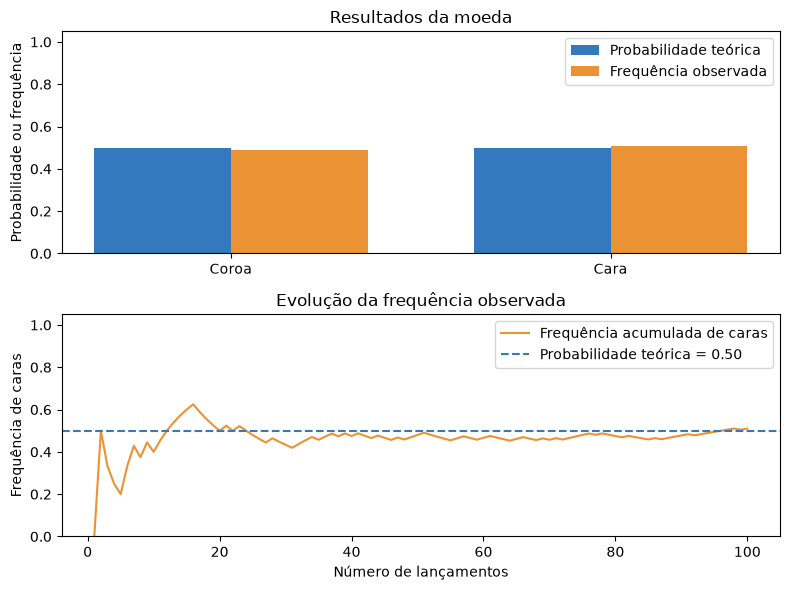

In [1]:
# IMPORTE AS BIBLIOTECAS DA DEMONSTRAÇÃO.
import numpy as np
import matplotlib.pyplot as plt

# DEFINA O MODELO E SIMULE OS LANÇAMENTOS.
p_cara = 0.5
n_lancamentos = 100
semente_moeda = 2026
rng_moeda = np.random.default_rng(semente_moeda)
dados_moeda = rng_moeda.binomial(1, p_cara, size=n_lancamentos)
eixo = np.arange(1, n_lancamentos + 1)
frequencias = np.cumsum(dados_moeda) / eixo
observadas = [1 - dados_moeda.mean(), dados_moeda.mean()]

# COMPARE PROBABILIDADES E FREQUÊNCIAS NO PAINEL SUPERIOR.
fig, axs = plt.subplots(2, 1, figsize=(8, 6))
axs[0].bar(np.array([0, 1]) - 0.18, [1 - p_cara, p_cara], width=0.36,
           color="#3478bd", label="Probabilidade teórica")
axs[0].bar(np.array([0, 1]) + 0.18, observadas, width=0.36,
           color="#eb9234", label="Frequência observada")
axs[0].set(xticks=[0, 1], xticklabels=["Coroa", "Cara"], ylim=(0, 1.05),
           ylabel="Probabilidade ou frequência", title="Resultados da moeda")
axs[0].legend()

# ACOMPANHE A FREQUÊNCIA ACUMULADA NO PAINEL INFERIOR.
axs[1].plot(eixo, frequencias, color="#eb9234", label="Frequência acumulada de caras")
axs[1].axhline(p_cara, color="#3478bd", linestyle="--",
               label=f"Probabilidade teórica = {p_cara:.2f}")
axs[1].set(xlabel="Número de lançamentos", ylabel="Frequência de caras",
           ylim=(0, 1.05), title="Evolução da frequência observada")
axs[1].legend()
fig.tight_layout()
plt.show()

**Figura 1 - Probabilidade teórica e frequência observada de cara.** O painel superior compara as probabilidades do modelo com as frequências em 100 lançamentos simulados. O inferior mostra que a frequência acumulada oscila em torno da probabilidade teórica de 0,50. Nesta sequência, foram observadas 51 caras, com frequência final de 0,51. Fonte: elaboração própria, com adaptação da proposta visual de SEEING THEORY ([s. d.]).

### 3.2 Conceituação

Seja $\Omega$ o espaço amostral e $\omega\in\Omega$ um resultado elementar. Definimos a variável aleatória por

$$
X:\Omega\longrightarrow\mathbb R,\qquad \omega\longmapsto x=X(\omega).\tag{2.1}
$$

Os valores possíveis formam $X(\Omega)=\{X(\omega):\omega\in\Omega\}$. Para um valor $x$, o evento $\{X=x\}=\{\omega\in\Omega:X(\omega)=x\}$ reúne os resultados que o produzem.

## 4. Variável aleatória discreta

Uma variável aleatória é discreta quando seus **valores possíveis** formam um conjunto finito ou enumerável (PINHEIRO et al., 2009, p. 115).

Considere dois lançamentos de moedas honestas e independentes. Denote cara por $C$ e coroa por $K$. Seja $X$ o número de caras. As hipóteses do modelo atribuem probabilidade $1/4$ a cada uma das quatro sequências possíveis (BARBETTA; REIS; BORNIA, 2010, p. 117–120).

### 4.1 Distribuição da contagem

O **espaço amostral** é $\Omega=\{CC,CK,KC,KK\}$ e os **valores possíveis** de $X$ são $\{0,1,2\}$. O **evento** $\{X=1\}$ reúne $CK$ e $KC$. Enumere os resultados em Python, sem simular lançamentos.

In [2]:
# IMPORTE AS FERRAMENTAS DE ENUMERAÇÃO E TABELA.
from itertools import product
import pandas as pd

# ENUMERE OS RESULTADOS E CONTE AS CARAS.
resultados = list(product("CK", repeat=2))
contagens = [resultado.count("C") for resultado in resultados]

# ORGANIZE OS RESULTADOS EM UMA TABELA.
tab_resultados = pd.DataFrame({
    "Resultado": ["".join(resultado) for resultado in resultados],
    "Número de caras": contagens,
    "Probabilidade do resultado": [1 / len(resultados)] * len(resultados),
})
tab_resultados

,Resultado,Número de caras,Probabilidade do resultado
0,CC,2,0.25
1,CK,1,0.25
2,KC,1,0.25
3,KK,0,0.25


**Tabela 1 - Resultados e contagem de caras.** As quatro sequências são equiprováveis sob as hipóteses declaradas; duas sequências distintas produzem uma cara.

Agrupe os resultados por valor da contagem. Uma **distribuição discreta** válida tem probabilidades não negativas cuja soma é 1. A formalização geral da função de probabilidade fica para a Unidade II.

In [3]:
# CONTE OS RESULTADOS CORRESPONDENTES A CADA VALOR E DIVIDA PELO TOTAL.
valores_x = sorted(set(contagens))
prob_d = [sum(valor == x for valor in contagens) / len(contagens) for x in valores_x]

# ORGANIZE A DISTRIBUIÇÃO EM UMA TABELA.
tab_distribuicao = pd.DataFrame({"Número de caras": valores_x, "Probabilidade": prob_d})
tab_distribuicao

,Número de caras,Probabilidade
0,0,0.25
1,1,0.50
2,2,0.25


**Tabela 2 - Distribuição do número de caras.** Os valores 0 e 2 têm probabilidade 0,25 cada; o valor 1 tem probabilidade 0,50 porque reúne duas sequências.

In [4]:
# VERIFIQUE AS PROPRIEDADES MÍNIMAS DA DISTRIBUIÇÃO.
print("Probabilidades não negativas:", sum(p >= 0 for p in prob_d) == len(prob_d))
print("Soma das probabilidades:", sum(prob_d))

Probabilidades não negativas: True
Soma das probabilidades: 1.0


### 4.2 Esperança

A **esperança** é o **centro teórico** da distribuição: cada valor possível recebe o peso de sua probabilidade (BARBETTA; REIS; BORNIA, 2010, p. 121–123; MORETTIN; BUSSAB, 2010, p. 152–153).

$$
\mathbb E[X]=\sum_{x\in X(\Omega)}x\,\mathbb P(X=x).\tag{2.2}
$$

Aqui, $x$ percorre os valores possíveis de $X$ e $\mathbb P(X=x)$ é o peso. A esperança tem a mesma unidade de $X$. Neste exemplo, ela é expressa em caras.

A esperança descreve o centro da distribuição e não precisa ser um resultado possível. Se $D$ representa a face de um dado justo, por exemplo, $\mathbb E[D]=3{,}5$, embora nenhuma face tenha esse valor.

A esperança é calculada com as probabilidades do modelo. A **média amostral** é calculada com os resultados observados. Implemente a soma em Python sem recorrer a uma função estatística pronta.

In [5]:
# SOME CADA VALOR POSSÍVEL PONDERADO POR SUA PROBABILIDADE.
media_d = sum(x * p for x, p in zip(valores_x, prob_d))
print(f"Esperança manual: {media_d:.6f} cara")

Esperança manual: 1.000000 cara


A esperança de **1 cara** significa que, em muitas repetições de dois lançamentos de moedas justas, a média do número de caras por tentativa tende a 1. Em uma tentativa, podem sair 0, 1 ou 2 caras. Esse valor é uma média teórica calculada com as probabilidades do modelo, não uma média de lançamentos observados.

O gráfico a seguir simula 300 pares de lançamentos de moedas honestas e independentes. Compare a **média observada** com a **esperança teórica** de 1 cara por par.

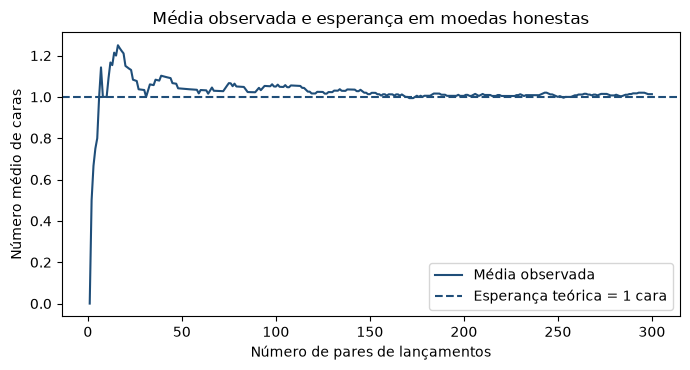

In [6]:
# IMPORTE AS BIBLIOTECAS DA DEMONSTRAÇÃO.
import numpy as np
import matplotlib.pyplot as plt

# DEFINA A DISTRIBUIÇÃO DO NÚMERO DE CARAS.
valores = np.array([0, 1, 2])
prob_moeda = np.array([0.25, 0.50, 0.25])
esperanca = sum(x * p for x, p in zip(valores, prob_moeda))
repeticoes = 300

# SIMULE OS PARES E CALCULE A MÉDIA ACUMULADA.
rng = np.random.default_rng(2026)
observados = rng.choice(valores, size=repeticoes, p=prob_moeda)
eixo = np.arange(1, repeticoes + 1)
medias = np.cumsum(observados) / eixo

# COMPARE A MÉDIA OBSERVADA COM A ESPERANÇA TEÓRICA.
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(eixo, medias, color="#1f4e79", label="Média observada")
ax.axhline(esperanca, color="#1f4e79", linestyle="--",
           label=f"Esperança teórica = {esperanca:g} cara")
ax.set(xlabel="Número de pares de lançamentos", ylabel="Número médio de caras",
       title="Média observada e esperança em moedas honestas")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**Figura 2 - Média observada e esperança em moedas honestas.** A curva mostra a média acumulada de caras por par de lançamentos. A linha tracejada marca a esperança de 1 cara. A média observada oscila e não precisa coincidir exatamente com esse valor após 300 pares.

### 4.3 Variância

A **variância** mede a **dispersão teórica** em torno da esperança, ponderando os **desvios quadráticos** pelas mesmas probabilidades (BARBETTA; REIS; BORNIA, 2010, p. 121–123).

$$
\operatorname{Var}(X)=\sum_{x\in X(\Omega)}(x-\mathbb E[X])^2\mathbb P(X=x).\tag{2.3}
$$

A esperança é o primeiro momento dos valores. A variância é o segundo momento dos desvios em relação à esperança (MORETTIN; BUSSAB, 2010, pp. 152–153).

A variância tem a unidade de $X$ ao quadrado. Neste exemplo, ela é expressa em caras ao quadrado. Não se usa o denominador $n-1$ da **variância amostral**.

Os desvios são elevados ao quadrado para que valores acima e abaixo da esperança não se anulem.

In [7]:
# SOME OS DESVIOS QUADRÁTICOS PONDERADOS.
variancia_d = sum((x - media_d) ** 2 * p for x, p in zip(valores_x, prob_d))
print(f"Variância manual: {variancia_d:.6f} cara²")

Variância manual: 0.500000 cara²


A esperança é **1 cara**. Os resultados 0 e 2 estão a uma cara dela e têm probabilidade **0,25 cada**. Cada um contribui com $1^2 \times 0,25 = 0,25$ para a variância. O resultado 1 tem desvio zero. Portanto, a variância é **0,5 cara²**.

Confira os **dois momentos** com uma distribuição discreta genérica do SciPy criada a partir da mesma tabela. A comparação confere a **implementação manual** para as probabilidades informadas; ela não testa a honestidade de moedas reais.

In [8]:
# IMPORTE A DISTRIBUIÇÃO DISCRETA DA BIBLIOTECA.
from scipy.stats import rv_discrete

# CONFIRA OS MOMENTOS COM A DISTRIBUIÇÃO DISCRETA DA BIBLIOTECA.
modelo_d = rv_discrete(name="duas_moedas", values=(valores_x, prob_d))
media_p, variancia_p = modelo_d.stats(moments="mv")
print(f"Esperança: Manual = {media_d:.6f}; Biblioteca = {float(media_p):.6f}")
print(f"Variância: Manual = {variancia_d:.6f}; Biblioteca = {float(variancia_p):.6f}")

Esperança: Manual = 1.000000; Biblioteca = 1.000000
Variância: Manual = 0.500000; Biblioteca = 0.500000


O próximo gráfico acompanha a média dos **desvios quadráticos observados** em relação à esperança teórica de 1 cara. Ela pode oscilar em torno da **variância teórica** de 0,5 cara². Essa curva não é a **variância amostral** calculada em torno da média observada.

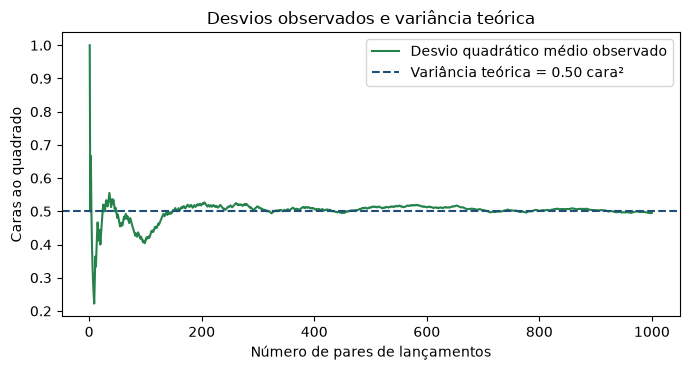

In [9]:
# DEFINA A DISTRIBUIÇÃO E CALCULE SEUS MOMENTOS.
valores = np.array([0, 1, 2])
prob = np.array([0.25, 0.50, 0.25])
esperanca = sum(x * p for x, p in zip(valores, prob))
variancia = sum((x - esperanca) ** 2 * p for x, p in zip(valores, prob))

# SIMULE OBSERVAÇÕES E ACUMULE OS DESVIOS QUADRÁTICOS.
rng = np.random.default_rng(2027)
observados = rng.choice(valores, size=1000, p=prob)
eixo = np.arange(1, len(observados) + 1)
desvios_acumulados = np.cumsum((observados - esperanca) ** 2) / eixo

# COMPARE OS DESVIOS OBSERVADOS COM A VARIÂNCIA TEÓRICA.
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(eixo, desvios_acumulados, color="#24824a", label="Desvio quadrático médio observado")
ax.axhline(variancia, color="#1f4e79", linestyle="--",
           label=f"Variância teórica = {variancia:.2f} cara²")
ax.set(xlabel="Número de pares de lançamentos", ylabel="Caras ao quadrado",
       title="Desvios observados e variância teórica")
ax.legend()
fig.tight_layout()
plt.show()

**Figura 3 - Desvios quadráticos observados e variância teórica.** A curva verde mostra a média acumulada dos desvios quadráticos em relação à esperança de 1 cara. A linha tracejada marca a variância teórica de 0,5 cara². Uma sequência finita pode terminar acima ou abaixo desse valor.

**Prática com o exemplo discreto.** Considere $Y$ o número de coroas nos mesmos dois lançamentos. Construa sua distribuição e compare esperança e variância calculadas diretamente com os resultados da biblioteca.

In [10]:
# RESOLVA A TRANSFERÊNCIA DISCRETA PARA O NÚMERO DE COROAS.
contagens_y = [resultado.count("K") for resultado in resultados]

# CONSTRUA A DISTRIBUIÇÃO E CALCULE OS MOMENTOS.
valores_y = sorted(set(contagens_y))
prob_y = [sum(valor == y for valor in contagens_y) / len(contagens_y) for y in valores_y]
media_y = sum(y * p for y, p in zip(valores_y, prob_y))
variancia_y = sum((y - media_y) ** 2 * p for y, p in zip(valores_y, prob_y))

# CONFIRA COM A BIBLIOTECA E APRESENTE OS RESULTADOS.
modelo_y = rv_discrete(name="duas_moedas_coroas", values=(valores_y, prob_y))
print("Y — valores de Y e probabilidades:", list(zip(valores_y, prob_y)))
print("Y — esperança (Manual / Biblioteca):", media_y, float(modelo_y.mean()))
print("Y — variância (Manual / Biblioteca):", variancia_y, float(modelo_y.var()))

Y — valores de Y e probabilidades: [(0, 0.25), (1, 0.5), (2, 0.25)]
Y — esperança (Manual / Biblioteca): 1.0 1.0
Y — variância (Manual / Biblioteca): 0.5 0.5


Pela simetria das moedas honestas, $Y$ e $X$ possuem a mesma distribuição, esperança e variância. Essa conclusão depende das hipóteses do modelo.

## 5. Variável aleatória contínua

Uma variável aleatória é modelada como contínua quando seus valores podem **variar ao longo de intervalos**, como ocorre com uma medição de tempo (PINHEIRO et al., 2009, p. 115).

Considere $T$ o tempo de resposta de uma consulta a um banco de dados, em **minutos**. O modelo adotado tem a seguinte densidade (BARBETTA; REIS; BORNIA, 2010, p. 145 do PDF):

$$
f_T(t)=
\begin{cases}
2e^{-2t}, & t\geq 0,\\
0, & t<0.
\end{cases}
$$

Nesse modelo, $T\geq0$ e a densidade diminui conforme o tempo aumenta. A expressão descreve uma hipótese probabilística, não tempos observados de um sistema real.

### 5.1 Valores contínuos e probabilidade de intervalo

Em um modelo contínuo, a probabilidade de $T$ estar entre $a$ e $b$ é a área sob a curva de densidade nesse intervalo.

Um valor isolado $t$ não delimita área. Por isso, $\mathbb P(T=t)=0$, embora $t$ continue sendo um valor possível.

A altura $f_T(t)$ da curva em um ponto não representa uma probabilidade (BARBETTA; REIS; BORNIA, 2010, p. 143–145; PINHEIRO et al., 2009, p. 128–129).

$$
\mathbb P(a\leq T\leq b)=\int_a^b f_T(t)\,dt.\tag{2.4}
$$

Aqui, $a$ e $b$ delimitam um intervalo de valores de $T$, $t$ é um valor possível e $f_T(t)$ é a densidade declarada. Os limites têm a mesma unidade de $T$. Neste exemplo, são medidos em minutos. A definição geral de densidade será aprofundada na Unidade II.

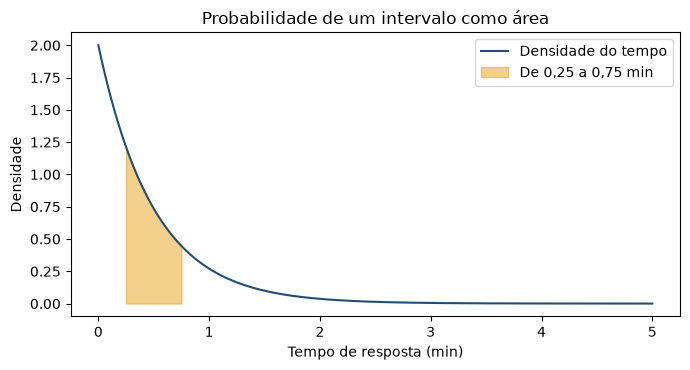

In [11]:
# IMPORTE AS BIBLIOTECAS DA VISUALIZAÇÃO.
import numpy as np
import matplotlib.pyplot as plt

# DEFINA A DENSIDADE DO TEMPO DE RESPOSTA.
def densidade_t(t):
    'Densidade exponencial do tempo de resposta, com taxa 2 por minuto.'
    return 2 * np.exp(-2 * t) if t >= 0 else 0.0

# PREPARE A CURVA E O INTERVALO SOMBREADO.
tempos = np.linspace(0, 5, 501)
densidades = [densidade_t(t) for t in tempos]

# MOSTRE A ÁREA CORRESPONDENTE À PROBABILIDADE DO INTERVALO.
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(tempos, densidades, color="#1f4e79", label="Densidade do tempo")
ax.fill_between(
    tempos, densidades, where=(tempos >= 0.25) & (tempos <= 0.75),
    color="#e69500", alpha=0.45, label="De 0,25 a 0,75 min"
)
ax.set(xlabel="Tempo de resposta (min)", ylabel="Densidade",
       title="Probabilidade de um intervalo como área")
ax.legend()
fig.tight_layout()
plt.show()

**Figura 4 - Área sob a densidade do tempo de resposta.** A faixa sombreada entre 0,25 e 0,75 minuto tem probabilidade aproximada de 0,3834 sob o modelo adotado. A curva continua além dos 5 minutos exibidos. A altura em um ponto isolado não é uma probabilidade.

Aproxime a área dividindo o intervalo em $n$ partes iguais de largura $h=(b-a)/n$ e somando retângulos avaliados nos **pontos médios**:

$$
\int_a^b g(t)\,dt\approx h\sum_{i=0}^{n-1}g\!\left(a+\left(i+\tfrac12\right)h\right).\tag{2.5}
$$

Aqui, $g$ é a função integrada e $n$ controla a resolução. Trata-se de uma **aproximação numérica**, não de integração simbólica.

In [12]:
# IMPLEMENTE A SOMA DAS ÁREAS DE RETÂNGULOS NOS PONTOS MÉDIOS.
def integrar_pontos_medios(funcao, a, b, n=10000):
    'Aproxima uma integral em intervalo finito por retângulos de ponto médio.'
    largura = (b - a) / n
    return largura * sum(funcao(a + (i + 0.5) * largura) for i in range(n))

Aproxime a área entre 0,25 e 0,75 minuto pela regra dos pontos médios e confira com a **integração numérica do SciPy**.

O suporte do modelo não tem limite superior. Para a integração manual da área total, use $[0,10]$ minutos. A probabilidade omitida acima de 10 minutos é $e^{-20}$, menor que $0,000000003$. A biblioteca integra até infinito. Calcule também $\mathbb P(T>3)$ como complemento da área entre 0 e 3 minutos.

Na conferência, `quad(funcao, a, b)` integra numericamente uma função entre os limites `a` e `b`. A função devolve o valor aproximado da integral e uma estimativa do erro. O índice `[0]` seleciona o valor da integral. Usamos `np.inf` quando o limite superior é infinito.

In [13]:
# IMPORTE A ROTINA DE INTEGRAÇÃO DA BIBLIOTECA.
from scipy.integrate import quad

# APROXIME AS ÁREAS EM INTERVALOS FINITOS.
limite_manual = 10.0
area_total_d = integrar_pontos_medios(densidade_t, 0, limite_manual)
area_intervalo_d = integrar_pontos_medios(densidade_t, 0.25, 0.75)
prob_maior_3_d = 1 - integrar_pontos_medios(densidade_t, 0, 3)

# CONFIRA COM A BIBLIOTECA, INCLUINDO A CAUDA INFINITA.
area_total_p = quad(densidade_t, 0, np.inf)[0]
area_intervalo_p = quad(densidade_t, 0.25, 0.75)[0]
prob_maior_3_p = quad(densidade_t, 3, np.inf)[0]

# COMPARE OS RESULTADOS.
print(f"Área total: Manual ≈ {area_total_d:.6f}; Biblioteca ≈ {area_total_p:.6f}")
print(f"Área no intervalo: Manual ≈ {area_intervalo_d:.6f}; Biblioteca ≈ {area_intervalo_p:.6f}")
print(f"P(T > 3): Manual ≈ {prob_maior_3_d:.6f}; Biblioteca ≈ {prob_maior_3_p:.6f}")

Área total: Manual ≈ 1.000000; Biblioteca ≈ 1.000000
Área no intervalo: Manual ≈ 0.383400; Biblioteca ≈ 0.383400
P(T > 3): Manual ≈ 0.002479; Biblioteca ≈ 0.002479


A área de 0 a 10 minutos é aproximadamente **1** e a integração da biblioteca sobre todo o suporte fornece **1**. A área sombreada vale aproximadamente **0,3834**. Nesse modelo, $\mathbb P(T>3)=e^{-6}\approx0,00248$, ou **0,248%** (BARBETTA; REIS; BORNIA, 2010, p. 145 do PDF). A concordância dos métodos confere os cálculos, não a adequação da densidade a um banco de dados real.

### 5.2 Esperança

A esperança continua a representar o **centro teórico**, agora ponderando continuamente os tempos pela densidade (BARBETTA; REIS; BORNIA, 2010, p. 146–147):

$$
\mathbb E[T]=\int_0^\infty t f_T(t)\,dt.\tag{2.6}
$$

A esperança tem a mesma unidade da variável aleatória. Neste exemplo, $t$ e $\mathbb E[T]$ são medidos em minutos, e $f_T(t)$ é a densidade. A implementação manual aproxima a integral até 10 minutos. A biblioteca integra até infinito.

In [14]:
# APROXIME A ESPERANÇA POR PONTOS MÉDIOS.
media_c = integrar_pontos_medios(
    lambda t: t * densidade_t(t), 0, limite_manual
)

# CONFIRA A ESPERANÇA COM A BIBLIOTECA.
media_c_p = quad(lambda t: t * densidade_t(t), 0, np.inf)[0]

# COMPARE AS DUAS ROTAS.
print(f"Esperança contínua: Manual ≈ {media_c:.6f} min; Biblioteca ≈ {media_c_p:.6f} min")

Esperança contínua: Manual ≈ 0.500000 min; Biblioteca ≈ 0.500000 min


A esperança é próxima de **0,5 minuto**, ou **30 segundos**. Sob esse modelo, é o tempo médio teórico de resposta em muitas consultas. Não é uma média observada de um banco de dados real.

**Prática com o exemplo contínuo.** Compare a aproximação da esperança de $T$ com 100 e 1.000 subintervalos em $[0,10]$ minutos e com a integração da biblioteca.

In [15]:
# COMPARE DUAS RESOLUÇÕES DA APROXIMAÇÃO COM A BIBLIOTECA.
for n in (100, 1000):
    estimativa = integrar_pontos_medios(
        lambda t: t * densidade_t(t), 0, limite_manual, n=n
    )
    print(f"{n} subintervalos: média ≈ {estimativa:.9f} min; diferença = {abs(estimativa - media_c_p):.9f} min")

100 subintervalos: média ≈ 0.500830400 min; diferença = 0.000830400 min
1000 subintervalos: média ≈ 0.500008311 min; diferença = 0.000008311 min


Neste exemplo, a diferença em relação à biblioteca diminui quando a malha fica mais fina. Ainda resta a pequena parcela além de 10 minutos omitida na implementação manual. A comparação avalia a aproximação numérica, não a adequação do modelo a dados reais.

### 5.3 Variância

A variância pondera os **desvios quadráticos** em relação à esperança (BARBETTA; REIS; BORNIA, 2010, p. 146–147):

$$
\operatorname{Var}(T)=\int_0^\infty\bigl(t-\mathbb E[T]\bigr)^2 f_T(t)\,dt.\tag{2.7}
$$

A esperança e cada desvio em relação a ela têm a mesma unidade da variável aleatória. Como a variância considera os desvios ao quadrado, sua unidade também fica ao quadrado. No exemplo, o desvio está em minutos e a variância em minutos ao quadrado.

A implementação manual aproxima a integral até 10 minutos. A biblioteca integra até infinito. Não se aplica a correção amostral por $n-1$.

In [16]:
# APROXIME A VARIÂNCIA POR PONTOS MÉDIOS.
variancia_c = integrar_pontos_medios(
    lambda t: (t - media_c) ** 2 * densidade_t(t), 0, limite_manual
)

# CONFIRA A VARIÂNCIA COM A BIBLIOTECA.
variancia_c_p = quad(
    lambda t: (t - media_c_p) ** 2 * densidade_t(t), 0, np.inf
)[0]

# COMPARE AS DUAS ROTAS.
print(f"Variância contínua: Manual ≈ {variancia_c:.6f} min²; Biblioteca ≈ {variancia_c_p:.6f} min²")

Variância contínua: Manual ≈ 0.250000 min²; Biblioteca ≈ 0.250000 min²


A variância é próxima de **0,25 min²**. Isso significa que a média teórica dos desvios quadráticos em relação à esperança de 0,5 minuto é 0,25 min². A conferência com a biblioteca avalia o cálculo para a densidade declarada, sem validar o modelo com dados reais.

## 6. Estudo e exercícios

### 6.1 Materiais didáticos

- BARBETTA; REIS; BORNIA (2010), seção 5.1, pp. 116–122: variável aleatória discreta, esperança e variância.
- MORETTIN; BUSSAB (2010), seção 6.3, pp. 135–136: esperança como média ponderada.
- PINHEIRO et al. (2009), seção 4.2, p. 98: tipos de variáveis aleatórias.
- BARBETTA; REIS; BORNIA (2010), seção 6.1, pp. 140–146, especialmente p. 144 para a densidade: densidade, área, esperança e variância no caso contínuo.

### 6.2 Exercícios indicados

- BARBETTA; REIS; BORNIA (2010), capítulo 5, exercício 1(c, d), p. 125: distribuição de peças defeituosas.
- PINHEIRO et al. (2009), exercício 4.3_P(a, b), p. 131: distribuição, média e desvio-padrão do número de gols.
- BARBETTA; REIS; BORNIA (2010), capítulo 6, exercício 1(a, c), p. 146: densidade, esperança e variância em $[0,1]$.

## 7. Referências

1. BARBETTA, Pedro Alberto; REIS, Marcelo Menezes; BORNIA, Antonio Cezar. *Estatística para cursos de engenharia e informática*. 3. ed. São Paulo: Atlas, 2010.
2. MORETTIN, Pedro A.; BUSSAB, Wilton O. *Estatística básica*. 6. ed. São Paulo: Saraiva, 2010.
3. PINHEIRO, João Ismael D. et al. *Estatística básica: a arte de trabalhar com dados*. Rio de Janeiro: Elsevier, 2009.
4. SEEING THEORY. *Basic probability*. [S. l.], [s. d.]. Disponível em: https://seeing-theory.brown.edu/basic-probability/index.html. Acesso em: 8 out. 2026.
